<a href="https://colab.research.google.com/github/beatriz-carrillo/connectatel-customer-usage-analysis/blob/main/ConnectaTel_Customer_Usage_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

###  Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print("users missing:", users.isna().sum())
print("users missing %:", users.isna().mean())

users missing: user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
users missing %: user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print("usage:", usage.isna().sum())
print("usage %:", usage.isna().mean())

usage: id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
usage %: id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?

**💡Diagnóstico de valores nulos**

**Dataset Plans:**
- No presenta valores nulos, por lo que no se requiere tratamiento adicional en esta etapa.
  
**Dataset users**
- city(11.73%): presenta valores faltantes. Se recomienda evaluar su imputación para conservar los registros y evitar la perdida de información.
- churn_date(88.35%): los nulos podrian representar clientes activos, se recomienda conservarlos y verificar su significado.
  
**Dataset usage**
- date(0.13%): pocos valores faltantes. Se recomienda revisar estos registros y considerar eliminarlos si no es posible recuperar la fecha.
- duration(55.19%): verificar si los valores nulos corresponden a registros de mensajes, ya esta variable podria aplicar unicamente a llamadas.
- lenght(44.74%): se recomienda investigar si los valores nulos son registros de llamadas, ya que esta variable podria aplicar unicamente a llamadas.


###  Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` contiene valores numéricos de los clientes, con valores entre 10000 y 13999. No requiere interpretación estadistica.
- La columna `age` presenta un valor mínimo de -999, identificado como un sentinel invalido que distorsiona la media y la desviacion estándar. Se recomienda tratarlo como valor faltante durante la limpieza.

In [ ]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`contienen identificadores numéricos de los registros y clientes, respectivamente. No requieren interpretación estadística.
- Las columnas duration y length presentan valores mínimos de 0 y máximos de 120 y 1490, respectivamente, lo que podría indicar valores atípicos. Se recomienda revisar estos valores antes de realizar la impieza.

In [ ]:

# explorar columnas categóricas de users
columnas_user = ["city", "plan"]

for col in columnas_user:
    print(col)
    print(users[col].unique())



city
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
plan
['Basico' 'Premium']


- La columna `city` presenta valores faltantes (NaN) y un posible sentinel (?), ademas hay nombres de ciudades abreviados. Se recomienda tratar valores inválidos y estandarizar los nombres durante la limpieza.
- La columna `plan` contiene dos categorías (Basico y Premium), sin inconsistencias evidentes. Se recomienda verificar la informacion con el catalogo de planes.

In [ ]:

# explorar columna categórica de usage
print(usage["type"].unique())


['call' 'text']


- La columna `type` contiene dos categorías (call y text). No se identifican valores invalidos no sentinels, por lo que no requiere limpieza adicional en esta etapa.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

### Diagnóstico de valores inválidos o sentinels
**Dataset 'users'**

- **'age':** Se identifica el sentinel (-999), que representa una edad inválida y distorsiona las estadísticas.
  **Acción:** Reemplazar por un valor nulo para su posterior tratamiento.
- **'city':** Se detectó el sentinel '?', además de valores nulos y nombres de ciudades abreviados.
  **Acción:** Reemplazar por un valor nulo y estandarizar los nombres de las ciudades.

**Dataset `usage`**
- **'duration' y 'length':** Presentan valores en cero y máximos elevados que podrían representar comportamientos atípicos.
  **Acción:** Investigar estos valores antes de determinar si requieren tratamiento.

**Validación de categorías**
- **`plan` y `type`:** No presentan valores inválidos evidentes.
  **Acción:** Validar los planes con el catálogo y conservar las categorías válidas de actividad.
  
**💡 Conclusión:** Se identificaron dos sentinels (`-999` y `"?"`) que requieren tratamiento durante la limpieza. Los posibles valores atípicos deberán analizarse antes de decidir si representan errores o comportamientos reales.

### Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:

# Convertir a fecha la columna `reg_date` de users
users["reg_date"] = pd.to_datetime(users["reg_date"],errors="coerce")


In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"],errors="coerce")

In [ ]:
# Revisar los años presentes en `reg_date` de users
users["reg_date"].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se observan fechas entre 2022 y 2024, dentro del período de análisis, y 40 registros del año 2026 (1%) fuera de rango. Se recomienda revisar y tratar estas fechas invalidas durante la limpieza.

In [ ]:
# Revisar los años presentes en `date` de usage
usage["date"].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date`, se observan 39,950 registros correspondientes al año 2024, sin fechas fuera de rango. Al extraer el año se muestra como 2024.0, se recomienda revisar estos registros.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

### Diagnóstico de fechas fuera de rango

**Dataset 'users'**
**'reg_date':** Se identificaron 40 registros del año 2026, fuera del período de análisis que finaliza en 2024. Se recomienda revisar estas fechas y tratarlas como valores nulos si no es posible corregirlas.

**📌 Dataset `usage`**

- **`date`:** Presenta 39,950 registros correspondientes al año 2024, sin fechas fuera de rango. Se identificaron 50 valores nulos (0.13%), por lo que se recomienda revisar y considerar eliminar estos registros si no es posible recuperar la fecha.

- **Formato del año:** Al extraer el año, se muestra como `2024.0` en lugar de `2024`. Se recomienda revisar su formato para presentarlo como número entero.

---

**💡 Conclusión:** Se identificaron fechas fuera de rango en `reg_date` y valores faltantes en `usage`. Estas inconsistencias deberán tratarse durante la limpieza para garantizar la calidad del análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
users.loc[users["age"] == -999, "age"] = np.nan
age_mediana = users["age"].median()
users["age"] = users["age"].fillna(age_mediana).astype(int)

# Verificar cambios
users["age"].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace(["?"], pd.NA)

# Verificar cambios
users["city"].describe()

# Contar sentinels en city
#(users["city"] == "?").sum()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [ ]:
# Marcar fechas futuras como NA para reg_date
users["reg_date"] = pd.to_datetime(users["reg_date"], errors="coerce")
users.loc[users["reg_date"] > "2024-12-31", "reg_date"] = pd.NaT

# Verificar cambios
users["reg_date"].describe()

#print(users["reg_date"].dtype)


count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

In [ ]:
# Porcentaje de valores faltantes después de la limpieza
users["city"].isna().mean() * 100

14.124999999999998

### Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duration_null"] = usage["duration"].isna()

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage["length_null"] = usage["length"].isna()

# Revisar valores nulos según el tipo de actividad
usage.groupby("type")[["duration_null", "length_null"]].sum()

,duration_null,length_null
type,,
call,0,17896
text,22076,0


### Diagnóstico de valores nulos en `usage`

- **`duration`:** Se identificaron 22,076 valores nulos correspondientes a mensajes (`text`), ya que los mensajes no tienen duración de llamada.

- **`length`:** Se identificaron 17,896 valores nulos, que corresponden a llamadas (`call`), ya que las llamadas no tienen longitud de mensaje.

**💡 Conclusión:** Los valores nulos dependen de la columna 'type' (MAR). Se recomienda consrvarlos como nulos, ya que corresponden a informacion que no aplica al tipo de actividad y no representan errores.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.



In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id")[["is_text","is_call","duration"]].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

# Verificar dimensiones
print("usage_agg:", usage_agg.shape)
print("user_profile:", user_profile.shape)


usage_agg: (3999, 4)
user_profile: (4000, 11)


### 💡 Insight: Integración de datos por usuario

- **Integración:** Se identificaron 3,999 usuarios con registros de actividad, frente a los 4,000 clientes del dataset original. Mediante `merge()` con `how="left"`, se conservaron todos los clientes.

- **Valores faltantes:** La diferencia indica que un cliente no cuenta con registros de consumo en `usage`. Se decidió conservar sus valores nulos hasta evaluar su significado y determinar el tratamiento adecuado.

**💡 Conclusión:** Se conservaron los 4,000 clientes para evitar la pérdida de información. El usuario sin actividad registrada se revisará posteriormente para evitar una clasificación incorrecta.

### Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.



In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile[["age","cant_mensajes","cant_llamadas","cant_minutos_llamada"]].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True) * 100



Basico     64.875
Premium    35.125
Name: plan, dtype: float64

In [ ]:
# Verificar dimensiones de los DataFrames
print("users:", users.shape)
print("usage_agg:", usage_agg.shape)
print("user_profile:", user_profile.shape)

users: (4000, 8)
usage_agg: (3999, 4)
user_profile: (4000, 11)


---
## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

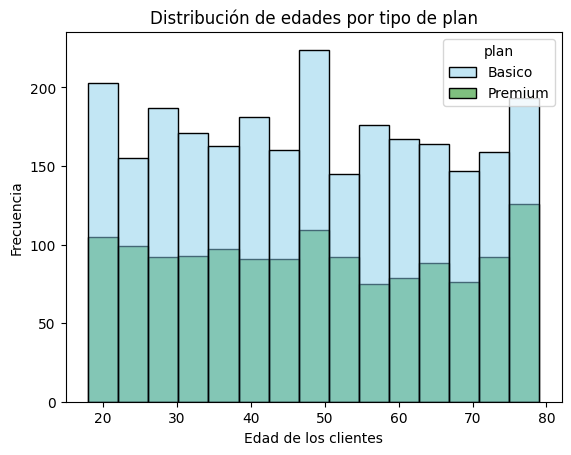

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,
    x="age",
    hue="plan",
    palette=["skyblue", "green"],
    bins=15
)

plt.title("Distribución de edades por tipo de plan")
plt.xlabel("Edad de los clientes")
plt.ylabel("Frecuencia")
plt.show()

### 💡Insights: Distribución de edades por tipo de plan
- **Distribución:** Las edades presentan una distribución relativamente uniforme entre los 18 y 79 años, sin un sesgo significativo hacia edades menores o mayores.

- **Comparación por plan:** El plan Básico presenta mayor frecuencia de clientes en todos los rangos de edad, mientras que Premium mantiene una distribución similar, pero con menor cantidad de usuarios.

- **Patrón identificado:** No se observan diferencias marcadas en la distribución de edades entre ambos planes, por lo que la edad no parece mostrar una relación clara con el tipo de plan contratado.

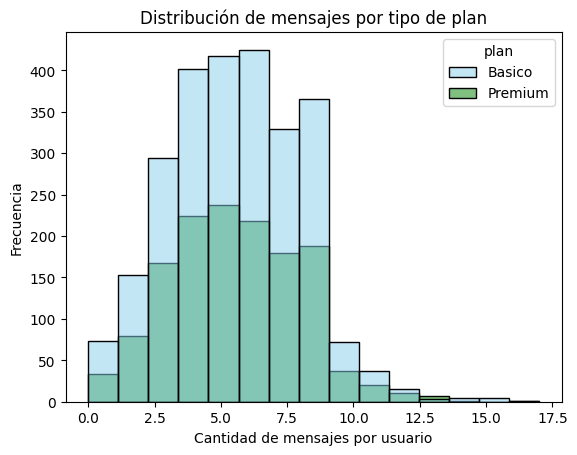

In [ ]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile,
    x="cant_mensajes",
    hue="plan",
    palette=["skyblue", "green"],
    bins=15
)

plt.title("Distribución de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes por usuario")
plt.ylabel("Frecuencia")
plt.show()




💡Insights: Distribución de mensajes por tipo de plan

- **Distribución:** La cantidad de mensajes presenta una distribución apoximadamente de campana, con mayor concentración entre 3 y 9 mensajes por usuario y un ligero sesgo hacia la derecha.

- **Comparación por plan:** Los clientes de los planes Básico y Premium muestran patrones similares de consumo, aunque el plan Básico registra mayores frecuencias debido a mayor numero de usuarios.

- **Valores extremos:** Se observan pocos usuarios con más de 12 mensajes, que podrían representar consumos atípicos y deberán revisarse posteriormente.


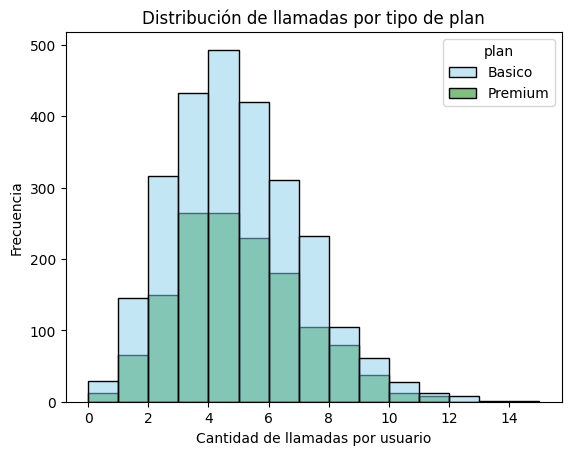

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile,
    x="cant_llamadas",
    hue="plan",
    palette=["skyblue", "green"],
    bins=15
)

plt.title("Distribución de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas por usuario")
plt.ylabel("Frecuencia")
plt.show()



### 💡 Insight: Distribución de llamadas por tipo de plan
- **Distribución:** La cantidad de llamadas presenta una distribución aproximadamente de campana, con un ligero sesgo hacia la derecha y mayor concentración entre 3 y 7 llamadas por usuario.

- **Comparación por plan:** Los clientes de los planes Básico y Premium muestran patrones similares de uso. El plan Básico presenta mayores frecuencias, posiblemente debido a su mayor cantidad de usuarios.

- **Valores extremos:** Se observan pocos usuarios con más de 11 llamadas, que podrían representar consumos atípicos y deberán analizarse posteriormente.

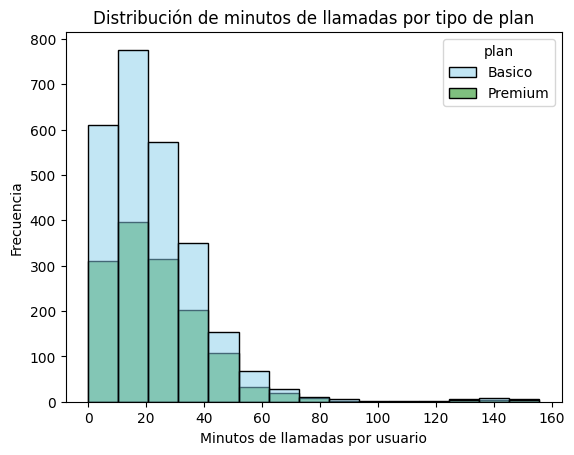

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile,
    x="cant_minutos_llamada",
    hue="plan",
    palette=["skyblue", "green"],
    bins=15
)

plt.title("Distribución de minutos de llamadas por tipo de plan")
plt.xlabel("Minutos de llamadas por usuario")
plt.ylabel("Frecuencia")
plt.show()


### 💡 Insight: Distribución de minutos de llamadas por tipo de plan

- **Distribución:** Presenta un sesgo hacia la derecha, con mayor concentración de usuarios entre 0 y 40 minutos de llamadas acumuladas.

- **Comparación por plan:** Los clientes de los planes Básico y Premium muestran patrones similares de consumo, aunque Básico presenta frecuencias más altas debido a su mayor cantidad de usuarios.

- **Valores extremos:** Se observan pocos usuarios con consumos superiores a 100 minutos, que podrían representar valores atípicos y deberán analizarse posteriormente.

### Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
- Después de crear los gráfico, responde si **existen o no outliers** en las variables.
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
- Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

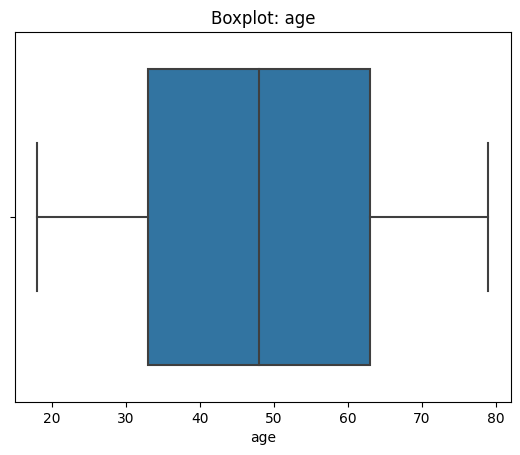

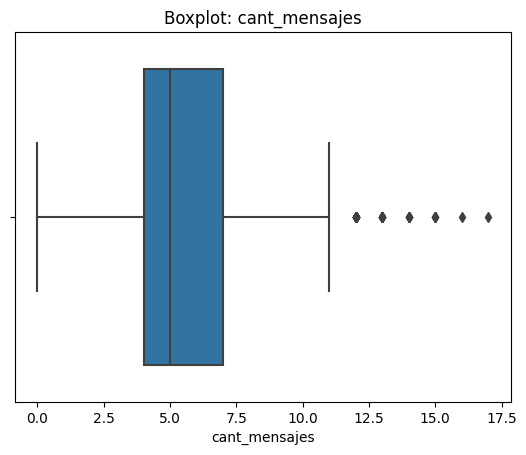

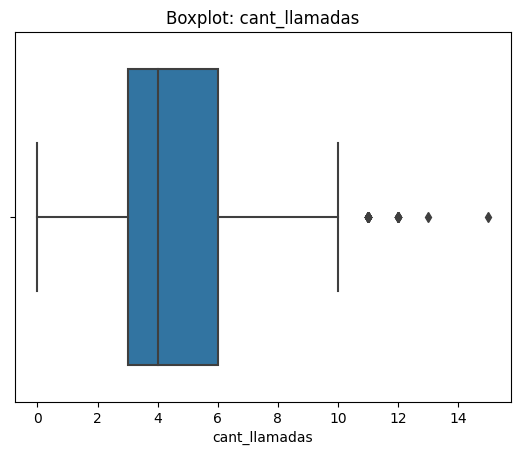

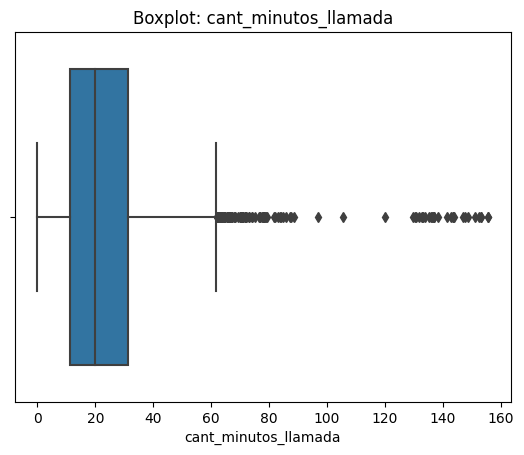

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f"Boxplot: {col}")
    plt.xlabel(col)
    plt.show()

💡Insights:
- **`age`:** No presenta valores atípicos. Las edades se encuentran dentro de los límites del boxplot, con una mediana cercana a 48 años.
- **`cant_mensajes`:** Presenta outliers superiores, principalmente en usuarios con más de 12 mensajes. Se recomienda calcular el límite superior mediante IQR antes de decidir su tratamiento.
- **`cant_llamadas`:** Presenta outliers superiores, con usuarios que realizan maás de 10 llamadas. Se recomienda calcular el límite superior mediante IQR para evaluar estos valores.
- **`cant_minutos_llamada`:** Presenta numerosos outliers superiores, con consumos que superan aproximadamente los 60 minutos y alcanzan valores cercanos a 150. Se recomienda investigar estos registros antes de decidir si requieren tratamiento.

---

**💡 Conclusión:** Se identificaron valores atípicos superiores en las tres variables de consumo, mientras que `age` no presenta outliers. Se aplicará el método IQR para determinar los límites superiores y evaluar si los valores extremos corresponden a comportamientos reales o posibles inconsistencias.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = [
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_superior = Q3 + 1.5 * IQR

print(col)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite superior:", limite_superior)
print("Valores atípicos:", (user_profile[col] > limite_superior).sum())
print()


cant_minutos_llamada
Q1: 11.12
Q3: 31.415
IQR: 20.295
Límite superior: 61.8575
Valores atípicos: 109



In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


### 💡 Insights: Identificación de outliers mediante IQR
- **`cant_mensajes`:** Se observan algunos usuarios con un consumo superior al habitual. Se recomienda conservar inicialmente los valores atípicos, ya que podrían representar usuarios con mayor actividad de mensajería.
- **`cant_llamadas`:** La mayoría de los usuarios presenta un consumo moderado, mientras que un grupo reducido realiza más llamadas. Se recomienda mantener los valores atípicos, sujetos a revisión, porque podrían corresponder a comportamientos reales de consumo.
- **`cant_minutos_llamada`:** Se identificaron 109 usuarios que superan el límite superior de 61.86 minutos, con un máximo de 155.69 minutos. Se recomienda conservarlos inicialmente y revisar los casos más extremos.

---

**💡 Conclusión:** Los valores atípicos se concentran en los niveles altos de consumo y no necesariamente representan errores. Conservarlos permitirá analizar diferentes patrones de uso e identificar posibles oportunidades de mejora en los planes comerciales.

---

## 🧩Paso 6: Segmentación de Clientes

### Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
user_profile["grupo_uso"] = np.where(
    (user_profile["cant_llamadas"] < 5) & (user_profile["cant_mensajes"] < 5),
    "Bajo uso",
    np.where(
        (user_profile["cant_llamadas"] < 10) & (user_profile["cant_mensajes"] < 10),
        "Uso medio",
        "Alto uso"
    )
)


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


In [ ]:
# Distribución porcentual de los segmentos
user_profile["grupo_uso"].value_counts(normalize=True) * 100

Uso medio    73.575
Bajo uso     19.450
Alto uso      6.975
Name: grupo_uso, dtype: float64

### Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos


In [ ]:
# Crear columna grupo_edad
user_profile["grupo_edad"] = np.where(
    (user_profile["age"] < 30),
    "Joven",
    np.where(
        (user_profile["age"] < 60),
        "Adulto",
        "Adulto Mayor"
    )
)


In [ ]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [ ]:
# Revisar segmentos por uso
print(user_profile["grupo_uso"].value_counts())

# Revisar segmentos por edad
print(user_profile["grupo_edad"].value_counts())

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64
Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [ ]:
# Revisar clientes sin datos de consumo
user_profile[
    user_profile["cant_mensajes"].isna() |
    user_profile["cant_llamadas"].isna()
][["user_id", "cant_mensajes", "cant_llamadas", "grupo_uso"]]


,user_id,cant_mensajes,cant_llamadas,grupo_uso
1082,11082,NaN,NaN,Alto uso


In [ ]:
# Corregir clasificación del usuario sin datos de consumo
user_profile["grupo_uso"] = np.where(
    user_profile["cant_mensajes"].isna() & user_profile["cant_llamadas"].isna(),
    "Sin datos",
    user_profile["grupo_uso"]
)
# Verificar cambios
user_profile["grupo_uso"].value_counts()

Uso medio    2943
Bajo uso      778
Alto uso      278
Sin datos       1
Name: grupo_uso, dtype: int64

In [ ]:
# Distribución porcentual del segmento edad
user_profile["grupo_edad"].value_counts(normalize=True) * 100

Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64

### 🔎Validación de la segmentación por uso

- **Hallazgo:** Se identificó un cliente sin registros de consumo que inicialmente quedó clasificado como "Alto uso".

- **Tratamiento:** Se asignó la categoría "Sin datos" para evitar una clasificación incorrecta.

- **Resultado:** Se conservaron los 4,000 clientes y se corrigió la segmentación antes de realizar las visualizaciones.

### Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

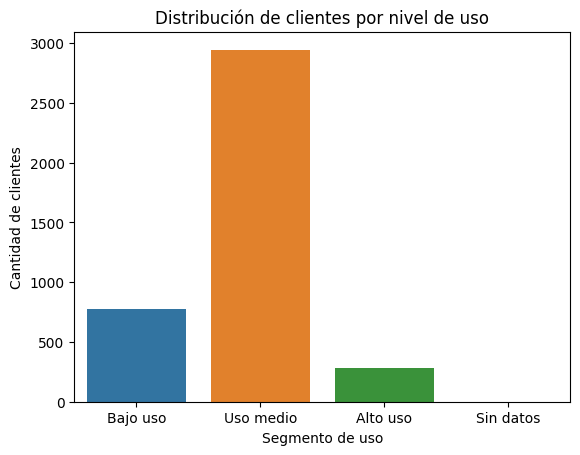

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x="grupo_uso",
    order=["Bajo uso","Uso medio","Alto uso","Sin datos"]
)

plt.title("Distribución de clientes por nivel de uso")
plt.xlabel("Segmento de uso")
plt.ylabel("Cantidad de clientes")
plt.show()



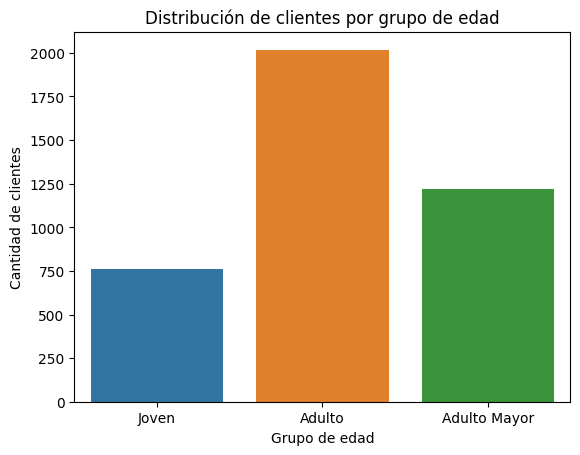

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x="grupo_edad",
    order=["Joven","Adulto","Adulto Mayor"]
)

plt.title("Distribución de clientes por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de clientes")
plt.show()




---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### 📊 Análisis Ejecutivo — ConnectaTel

El análisis de ConnectaTel permitió identificar patrones de uso de llamadas y mensajes, diferencias entre segmentos de clientes y comportamientos atípicos que pueden contribuir a mejorar la oferta comercial y la experiencia del usuario.

⚠️ **1. Problemas detectados en los datos**
- **Valores inválidos:** Se identificaron sentinels en `age` (-999) y `city` ("?"), que fueron tratados durante la limpieza. La columna `city` registró 565 valores faltantes (14.13%), mientras que la edad fue corregida mediante imputación con la mediana.
- **Fechas inconsistentes:** Se detectaron 40 registros (1%) con fechas de 2026, fuera del periodo de análisis hasta 2024, que fueron reemplazados por valores nulos.
- **Registros de consumo:** Se comprobó que los nulos de `duration` y `length` dependen del tipo de actividad (`call` o `text`), por lo que se conservaron.
- **Integración de datos:** Se mantuvieron los 4,000 clientes originales, identificando uno sin información de consumo que fue clasificado como "Sin datos".

**💡 Impacto:** La limpieza permitió corregir inconsistencias que podían distorsionar las estadísticas y afectar la clasificación de los clientes.

---

#### 🔍 2. Segmentos de clientes y patrones de consumo

📊 **Segmentos por Nivel de Uso**

- **Uso medio (73.58%):** Constituye el segmento predominante. La mayoría de los clientes presenta un consumo moderado de llamadas y mensajes, por lo que representa un grupo prioritario para evaluar la adecuación de los planes actuales.
- **Bajo uso (19.45%):** Agrupa clientes con menor actividad registrada, que podrían beneficiarse de ofertas más flexibles y ajustadas a su consumo.
- **Alto uso (6.95%):** Representa una proporción reducida de usuarios con mayor actividad. Este segmento podría requerir beneficios adicionales o alternativas de mayor capacidad.


📊 **Segmentos por edad**
- Los **Adultos (30–59 años)** representan el 50.45% de los clientes, seguidos de Adultos Mayores (30.55%) y Jóvenes (19%).
- Los histogramas muestran una distribución de edades relativamente uniforme entre los planes Básico y Premium, sin diferencias marcadas en su forma.
- Aunque la cartera se concentra en adultos, aún es necesario comparar el consumo por grupo de edad para determinar cuáles utilizan más llamadas y mensajes.

**💡 Insight:** El nivel de consumo permite distinguir necesidades de servicio diferentes. Sin embargo, la edad por sí sola no demuestra un mayor o menor uso de los servicios.

---

#### 📈 3. Comportamientos atípicos y posibles riesgos

- **Mensajes y llamadas:** Se identificaron valores atípicos superiores, correspondientes a usuarios con niveles de actividad mayores que los habituales.
- **Minutos de llamadas:** Se detectaron 109 usuarios que superan el límite IQR de 61.86 minutos, alcanzando un máximo de 155.69 minutos acumulados.
- **Interpretación:** Estos consumos podrían representar clientes intensivos, comportamientos inusuales o registros que requieren validación adicional.

**💡Se recomienda** conservar inicialmente los outliers y revisar los casos extremos antes de considerar su eliminación. La presencia de valores atípicos no constituye por sí sola evidencia de fraude o errores de registro.

---

#### 🎯 4. Segmentos con mayor potencial comercial

- **Uso medio:** Es el segmento de mayor tamaño y representa una oportunidad para optimizar la oferta actual y mejorar la satisfacción de una proporción importante de clientes.
- **Alto uso:** Podría presentar oportunidades de migración a planes con mayores beneficios, siempre que el consumo real justifique la propuesta.
- **Bajo uso:** Podría beneficiarse de planes económicos o flexibles que reduzcan la percepción de pagar por servicios que no utiliza.

**💡 Consideración:** El potencial comercial no equivale necesariamente a rentabilidad. Para identificar los segmentos de mayor valor económico se requiere complementar el análisis con ingresos, costos y comportamiento de abandono (`churn`).

---

#### 💡 5. Recomendaciones comerciales

1. **Optimizar la oferta para Uso medio:** Evaluar si los beneficios de los planes actuales corresponden al consumo habitual de la mayoría de los clientes, buscando mejorar su satisfacción y permanencia.

2. **Desarrollar ofertas diferenciadas:** Explorar alternativas flexibles para Bajo uso y beneficios adicionales para Alto uso, evitando propuestas generales que no respondan a necesidades específicas.

3. **Profundizar la segmentación:** Comparar el consumo por edad y tipo de plan para identificar grupos con comportamientos diferenciados y orientar mejor las campañas comerciales.

4. **Monitorear consumos atípicos:** Revisar los usuarios con niveles elevados de actividad para distinguir oportunidades comerciales de posibles anomalías operativas.

5. **Fortalecer la retención:** Analizar posteriormente la relación entre consumo, plan contratado y `churn` para identificar segmentos con mayor riesgo de abandono y diseñar acciones preventivas.

---

#### ✅ Conclusión Ejecutiva

ConnectaTel presenta una cartera concentrada principalmente en clientes de uso medio (73.58%) y adultos de 30 a 59 años (50.45%). Además, se identificaron grupos de bajo y alto consumo con necesidades potencialmente diferentes, así como usuarios con comportamientos atípicos que requieren seguimiento.

Los resultados sugieren que una estrategia comercial basada en el comportamiento de uso podría contribuir a mejorar la personalización de los planes y la experiencia del cliente.

**La principal oportunidad para ConnectaTel es pasar de una oferta general a una segmentación comercial basada en datos**, validando posteriormente las propuestas mediante comparaciones de consumo por edad, plan contratado y métricas de rentabilidad y retención.


## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.


Link a repositorio público del proyecto: `LINK a tu repo aquí`